# 2020 — SimCLR: Self-Supervised Contrastive Learning

**Papers:** Ting Chen, Simon Kornblith, Mohammad Norouzi & Geoffrey Hinton, *"A Simple Framework for Contrastive Learning of Visual Representations"* (SimCLR, 2020); He et al., *MoCo* (2019); Grill et al., *BYOL* (2020); later DINO (2021), MAE (2021), DINOv2 (2023).

Can a network learn good features **without any labels**? SimCLR's recipe:
1. Take an image and make **two random augmentations** of it (crop, shift, rotate, noise, ...)
2. Encode both with the same network $f$, then pass them through a small **projection head** $g$
3. **NT-Xent loss:** the two views of the same image should be close, and views of *other* images in the batch far apart:
$$\ell_{i,j} = -\log \frac{\exp(\operatorname{sim}(z_i, z_j)/\tau)}{\sum_{k\neq i}\exp(\operatorname{sim}(z_i, z_k)/\tau)}$$

The network has to learn what stays the same under augmentation, which turns out to be *what the object is*. Evaluate with a **linear probe**: freeze the encoder and train only a linear classifier on its features. CLIP (notebook 51) applies the same contrastive loss across images and text.

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


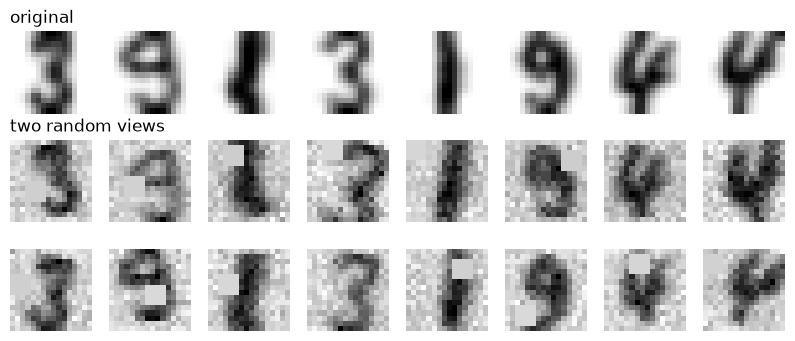

In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

def load_digits_tensors(size=8, test_size=0.2, seed=0):
    """sklearn's bundled 8x8 handwritten digits (1,797 images, no download needed).
    Returns X_train, y_train, X_test, y_test with X shaped (N, 1, size, size) in [0, 1]."""
    d = load_digits()
    X = torch.tensor(d.images, dtype=torch.float32).unsqueeze(1) / 16.0
    if size != 8:
        X = F.interpolate(X, size=(size, size), mode="bilinear", align_corners=False)
    y = torch.tensor(d.target, dtype=torch.long)
    tr, te = train_test_split(np.arange(len(y)), test_size=test_size, random_state=seed, stratify=d.target)
    return X[tr], y[tr], X[te], y[te]
Xtr, ytr, Xte, yte = [t.to(device) for t in load_digits_tensors(size=16)]

def augment(x):
    """Random shift (crop after padding), small rotation + scale, pixel noise and random erasing."""
    B = len(x)
    ang = (torch.rand(B, device=x.device) - 0.5) * 0.6; sc = 1 + (torch.rand(B, device=x.device) - 0.5) * 0.3
    tx, ty = (torch.rand(2, B, device=x.device) - 0.5) * 0.4
    theta = torch.stack([torch.stack([sc * torch.cos(ang), -sc * torch.sin(ang), tx], 1),
                         torch.stack([sc * torch.sin(ang), sc * torch.cos(ang), ty], 1)], 1)
    x = F.grid_sample(x, F.affine_grid(theta, x.shape, align_corners=False), align_corners=False)
    x = x + 0.1 * torch.randn_like(x)
    erase = torch.rand(B, device=x.device) < 0.5
    i, j = torch.randint(0, 12, (2,))
    x[erase, :, i:i + 4, j:j + 4] = 0
    return x

fig, axes = plt.subplots(3, 8, figsize=(10, 4))
for j in range(8):
    axes[0, j].imshow(Xtr[j, 0].cpu(), cmap="gray_r")
    axes[1, j].imshow(augment(Xtr[j:j + 1])[0, 0].cpu(), cmap="gray_r"); axes[2, j].imshow(augment(Xtr[j:j + 1])[0, 0].cpu(), cmap="gray_r")
for a in axes.flat: a.axis("off")
axes[0, 0].set_title("original", loc="left"); axes[1, 0].set_title("two random views", loc="left"); plt.show()

In [3]:
def encoder():
    return nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
                         nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
                         nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.AdaptiveAvgPool2d(1), nn.Flatten())

def nt_xent(z1, z2, tau=0.5):
    z = F.normalize(torch.cat([z1, z2]), dim=1)
    sim = z @ z.T / tau
    sim.fill_diagonal_(float("-inf"))                                  # never match a view with itself
    n = len(z1)
    targets = torch.cat([torch.arange(n, 2 * n), torch.arange(0, n)]).to(z.device)   # the positive is the other view
    return F.cross_entropy(sim, targets)

seed_everything(0)
f = encoder().to(device); g = nn.Sequential(nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, 64)).to(device)
opt = torch.optim.Adam(list(f.parameters()) + list(g.parameters()), lr=2e-3, weight_decay=1e-5)
t0 = time.time()
for step in range(1500):
    x = Xtr[torch.randint(0, len(Xtr), (256,), device=device)]       # labels never used
    loss = nt_xent(g(f(augment(x))), g(f(augment(x))))
    opt.zero_grad(); loss.backward(); opt.step()
    if step % 300 == 0: print(f"step {step:4d}  NT-Xent loss {loss.item():.3f}")
print(f"pre-trained without labels in {time.time() - t0:.0f}s")

step    0  NT-Xent loss 6.202


step  300  NT-Xent loss 4.547


step  600  NT-Xent loss 4.520


step  900  NT-Xent loss 4.503


step 1200  NT-Xent loss 4.470


pre-trained without labels in 28s


## Linear probe: how good are the features?
Freeze the encoder and train a logistic-regression classifier on its 128-d features, with all labels and with only 1 label per 10 images. Compare against a randomly initialised encoder and a fully supervised one.

In [4]:
from sklearn.linear_model import LogisticRegression
@torch.no_grad()
def feats(enc, X): enc.eval(); return enc(X).cpu().numpy()

def probe(enc, frac=1.0):
    n = int(len(Xtr) * frac); Ftr, Fte = feats(enc, Xtr[:n]), feats(enc, Xte)
    clf = LogisticRegression(max_iter=3000).fit(Ftr, ytr[:n].cpu()); return clf.score(Fte, yte.cpu())

seed_everything(0); rand_enc = encoder().to(device)
seed_everything(0); sup = nn.Sequential(encoder(), nn.Linear(128, 10)).to(device); o = torch.optim.Adam(sup.parameters(), lr=2e-3)
for _ in range(1500):
    idx = torch.randint(0, len(Xtr), (128,), device=device)
    l = F.cross_entropy(sup(augment(Xtr[idx])), ytr[idx]); o.zero_grad(); l.backward(); o.step()
print(f"{'encoder':32s} {'100% labels':>12s} {'10% labels':>12s}")
for name, enc in [("random init (no training)", rand_enc), ("SimCLR (no labels)", f), ("supervised (all labels)", sup[0])]:
    print(f"{name:32s} {probe(enc):12.3f} {probe(enc, 0.1):12.3f}")

encoder                           100% labels   10% labels


random init (no training)               0.567        0.100
SimCLR (no labels)                      0.997        0.958
supervised (all labels)                 0.997        0.994


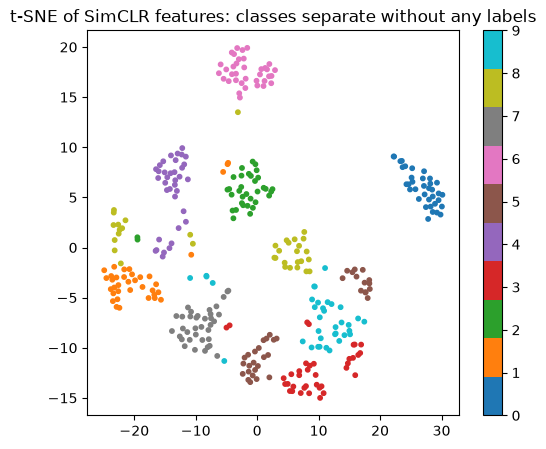

In [5]:
from sklearn.manifold import TSNE
Z = TSNE(2, random_state=0, init="pca").fit_transform(feats(f, Xte))
plt.figure(figsize=(6, 5)); sc = plt.scatter(Z[:, 0], Z[:, 1], c=yte.cpu(), cmap="tab10", s=10)
plt.colorbar(sc, ticks=range(10)); plt.title("t-SNE of SimCLR features: classes separate without any labels"); plt.show()